<!-- reader-content -->

# Fluxonium spectroscopy

<!-- notebook-download -->

Stefanski *et al.* measured a fluxonium and its readout resonator versus external flux.
Their paper, [*Improved fluxonium readout through dynamic flux
pulsing*](https://arxiv.org/abs/2411.13437), reports the fitted circuit parameters and the
readout operating points. The authors also publish their [analysis and modelling
code](https://github.com/AndersenQubitLab/FPA-RO-experimental) and the [measurement
archive](https://doi.org/10.4121/1092cb12-9198-4d43-8500-401c78a5dc15).

Does one quchip model reproduce their data, and does a gradient fit recover
the circuit energies? First reproduce the qubit spectrum with one
`Fluxonium` and the authors' parameters, then add the readout resonator.
Last, fit the circuit energies to part of the spectrum with JAX gradients
and test the fit on the rest. Frequencies are in GHz.

## Load the published measurements

`processed_data_fx8.csv` contains measured qubit frequencies and the
authors' fitted parameters. `res_fit_results.csv` contains the conditional
resonator frequencies and the paper's $\chi_{\rm paper}=(f_{r,1}-f_{r,0})/2$.
We convert these data to quchip's coefficient $\chi_Z=-\chi_{\rm paper}$,
with $Z=|0\rangle\langle0|-|1\rangle\langle1|$.

In [1]:
import csv
import io
import json
from urllib.request import urlopen

import numpy as np

from quchip import Chip, CouplingModel, Exact, Fluxonium, Resonator, Scalar, parameter

paper_data_root = (
    "https://raw.githubusercontent.com/AndersenQubitLab/"
    "FPA-RO-experimental/57dc268dd048d1372db082c3ddd97a04871580bf"
)


def published_rows(filename):
    url = f"{paper_data_root}/{filename}"
    with urlopen(url) as response:  # noqa: S310 - fixed public research archive
        return list(csv.DictReader(io.StringIO(response.read().decode("utf-8"))))


spectrum_rows = published_rows("processed_data_fx8.csv")
readout_rows = published_rows("res_fit_results.csv")

fitted_values = np.asarray(
    [float(spectrum_rows[index]["energy_params"]) for index in range(5)]
)
resonator_frequency, readout_coupling, paper_E_J, paper_E_C, paper_E_L = fitted_values

print(f"E_J = {paper_E_J:.4f} GHz, E_C = {paper_E_C:.4f} GHz, E_L = {paper_E_L:.4f} GHz")
print(f"Readout resonator: {resonator_frequency:.4f} GHz, coupling g = {1e3 * readout_coupling:.2f} MHz")

E_J = 3.8217 GHz, E_C = 0.8653 GHz, E_L = 0.8216 GHz
Readout resonator: 5.1751 GHz, coupling g = 37.16 MHz


## Reproduce the qubit spectrum

Figure 2 of the paper covers $0.5\leq\Phi_{\mathrm{ext}}/\Phi_0\leq0.85$, and
the model curve uses 351 evenly spaced flux values, more than twice the
measurement density. To evaluate the residuals, we interpolate that
independent curve at the measured coordinates. quchip receives the authors'
fitted energies unchanged.

In [2]:
paper_flux_all = np.asarray(
    [float(row["phi_ext_qubit"]) for row in spectrum_rows if row["phi_ext_qubit"]]
)
measured_f01_all = np.asarray(
    [float(row["qubit_freq"]) for row in spectrum_rows if row["qubit_freq"]]
)
figure_2_window = paper_flux_all <= 0.85
paper_flux = paper_flux_all[figure_2_window]
measured_f01 = measured_f01_all[figure_2_window]


def isolated_f01(phi_ext):
    q = Fluxonium(
        E_C=paper_E_C,
        E_J=paper_E_J,
        E_L=paper_E_L,
        phi_ext=phi_ext,
        levels=4,
        num_basis=300,
        phi_max=5.0 * np.pi,
        basis="eigen",
        label="q",
    )
    return float(q.freq)


Evaluate the spectrum on its own flux grid and compare it with the measured points.

In [3]:
paper_model_flux = np.linspace(0.5, 0.85, 351)
predicted_f01_grid = np.asarray([isolated_f01(phi) for phi in paper_model_flux])
predicted_f01_at_data = np.interp(paper_flux, paper_model_flux, predicted_f01_grid)
f01_residual_mhz = 1.0e3 * (predicted_f01_at_data - measured_f01)

<details>
<summary>Plotting code</summary>

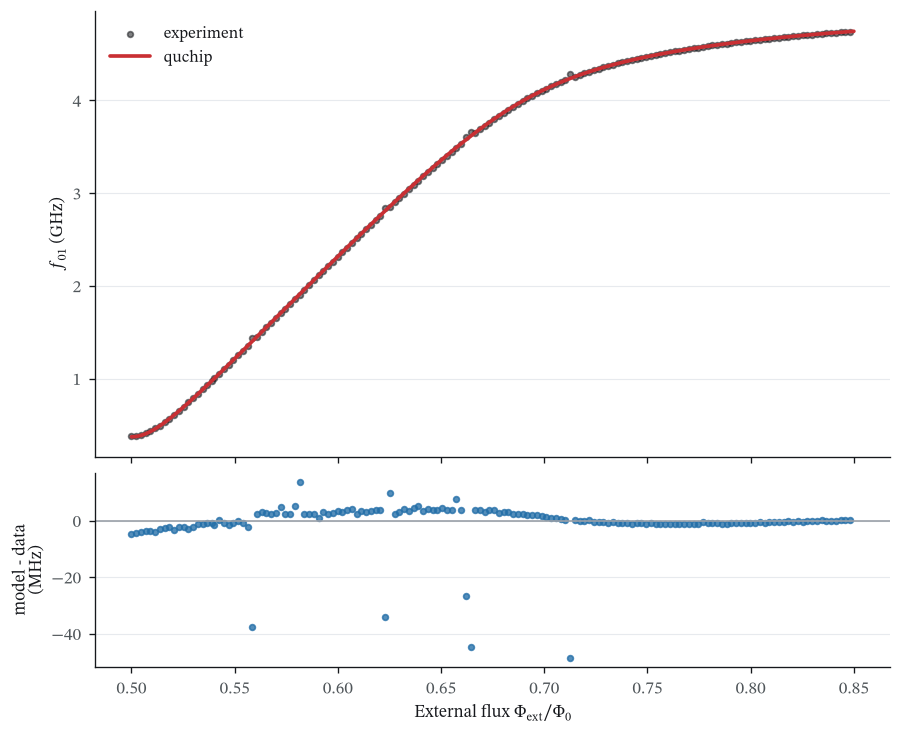

In [4]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt

# In a quchip checkout, use the documentation style and save the figures there.
docs = Path("../docs")
if docs.is_dir():
    plt.style.use(docs / "_static/quchip.mplstyle")
plt.rcParams["text.usetex"] = bool(shutil.which("latex"))

paper_spectrum_figure, (spectrum_axis, residual_axis) = plt.subplots(
    2,
    1,
    figsize=(7.4, 6.0),
    sharex=True,
    gridspec_kw={"height_ratios": [2.3, 1.0]},
    layout="constrained",
)
spectrum_axis.scatter(
    paper_flux,
    measured_f01,
    s=12,
    color="#16181C",
    alpha=0.55,
    label="experiment",
)
spectrum_axis.plot(
    paper_model_flux,
    predicted_f01_grid,
    color="#C92F33",
    linewidth=2.2,
    label="quchip",
)
spectrum_axis.set_ylabel(r"$f_{01}$ (GHz)")
spectrum_axis.legend()

residual_axis.axhline(0.0, color="#9AA0A8", linewidth=1.0)
residual_axis.scatter(paper_flux, f01_residual_mhz, s=12, color="#246FA8", alpha=0.78)
residual_axis.set(
    xlabel=r"External flux $\Phi_{\mathrm{ext}}/\Phi_0$",
    ylabel="model - data\n(MHz)",
)

if docs.is_dir():
    paper_spectrum_figure.savefig(docs / "images/stefanski_fluxonium_spectrum.svg")
plt.show()

</details>

```{figure} ../images/stefanski_fluxonium_spectrum.svg
:width: 720px
:alt: Measured fluxonium transition frequencies, quchip prediction, and pointwise residuals across external flux

The authors' fitted fluxonium energies reproduce the measured frequency curve.
Every extracted point in the paper's Figure 2 window is shown.
```

In [5]:
spectrum_check = {
    "measurement_points": len(measured_f01),
    "median_absolute_error_mhz": float(np.median(np.abs(f01_residual_mhz))),
    "p95_absolute_error_mhz": float(np.quantile(np.abs(f01_residual_mhz), 0.95)),
    "rmse_mhz": float(np.sqrt(np.mean(f01_residual_mhz**2))),
    "points_above_10_mhz": int(np.count_nonzero(np.abs(f01_residual_mhz) > 10.0)),
}
print(f"{spectrum_check['measurement_points']} measured points")
print(f"Absolute error: median {spectrum_check['median_absolute_error_mhz']:.2f} MHz, "
      f"95th percentile {spectrum_check['p95_absolute_error_mhz']:.2f} MHz")
print(f"RMSE {spectrum_check['rmse_mhz']:.2f} MHz, {spectrum_check['points_above_10_mhz']} points above 10 MHz")

153 measured points
Absolute error: median 1.59 MHz, 95th percentile 6.08 MHz
RMSE 7.57 MHz, 6 points above 10 MHz


The six residuals above 10 MHz stay in the plot and in the RMSE. The median
and 95th percentile describe the rest of the curve, and no points are
deleted.

## Add the readout resonator

The released model couples a resonator to the fluxonium oscillator coordinate
$c$ through $g(ca^\dagger+c^\dagger a)$. `CouplingModel` is quchip's public
extension point for defining that interaction without changing the device
models.

In [6]:
class FluxoniumReadoutCoupling(CouplingModel):
    """Exchange interaction used in the authors' released readout model."""

    g: Scalar = parameter(unit="GHz")
    oscillator_length: Scalar = parameter(positive=True)

    def interaction(self, q, r, p):
        scale = np.sqrt(2.0)
        lowering = q.phi * (1.0 / (p.oscillator_length * scale)) + (
            1j * p.oscillator_length / scale
        ) * q.charge
        raising = q.phi * (1.0 / (p.oscillator_length * scale)) - (
            1j * p.oscillator_length / scale
        ) * q.charge
        return p.g * (lowering * r.adag + raising * r.a)


Use the published interaction with the fitted circuit parameters, and keep
every coupling band with `Exact()`, since counter-rotating terms contribute
strongly to the fluxonium's dispersive shift: under `RWA()` the $\chi_Z$ RMSE
against the data increases from 0.77 MHz to 1.42 MHz.

In [7]:
paper_q = Fluxonium(
    E_C=paper_E_C,
    E_J=paper_E_J,
    E_L=paper_E_L,
    phi_ext=0.5,
    levels=10,
    num_basis=300,
    phi_max=5.0 * np.pi,
    basis="eigen",
    label="q",
)
paper_readout = Resonator(freq=resonator_frequency, levels=3, label="readout")
paper_edge = FluxoniumReadoutCoupling(
    paper_q,
    paper_readout,
    g=readout_coupling,
    oscillator_length=(8.0 * paper_E_C / paper_E_L) ** 0.25,
    label="q-readout",
)

paper_chip = Chip(
    [paper_q, paper_readout],
    [paper_edge],
    basis="eigen",
    frame="lab",
    approximation=Exact(),
)

`chip.freq("readout")` is the resonator transition with the qubit in
$|0\rangle$, and `chip.dispersive_shift()` returns the full state-dependent
pull, whose negative half is $\chi_Z$, the coefficient of $Z n_r$ in $H/h$.

In [8]:
readout_rows = [row for row in readout_rows if row["phi_ext_disshift"]]
readout_flux_all = np.asarray([float(row["phi_ext_disshift"]) for row in readout_rows])
measured_fr0_all = np.asarray([float(row["fr_q0"]) for row in readout_rows])
measured_fr1_all = np.asarray([float(row["fr_q1"]) for row in readout_rows])
measured_chi_all = -np.asarray([float(row["chi"]) for row in readout_rows])

readout_window = readout_flux_all <= 0.85
readout_flux = readout_flux_all[readout_window]
measured_fr0 = measured_fr0_all[readout_window]
measured_fr1 = measured_fr1_all[readout_window]
measured_chi_mhz = measured_chi_all[readout_window]


At each flux, ask the same chip for the two conditional readout frequencies.

In [9]:
def readout_observables(phi_ext):
    point = paper_chip.with_params({"q.phi_ext": phi_ext})
    fr0 = float(point.freq("readout"))
    full_pull = float(point.dispersive_shift("q", "readout"))
    return fr0, fr0 + full_pull, -500.0 * full_pull


readout_model_flux = np.linspace(0.5, 0.85, 351)
predicted_readout_grid = np.asarray(
    [readout_observables(phi) for phi in readout_model_flux]
)
predicted_fr0_grid = predicted_readout_grid[:, 0]
predicted_fr1_grid = predicted_readout_grid[:, 1]
predicted_chi_grid_mhz = predicted_readout_grid[:, 2]

predicted_fr0_at_data = np.interp(readout_flux, readout_model_flux, predicted_fr0_grid)
predicted_fr1_at_data = np.interp(readout_flux, readout_model_flux, predicted_fr1_grid)
predicted_chi_at_data_mhz = np.interp(
    readout_flux,
    readout_model_flux,
    predicted_chi_grid_mhz,
)

<details>
<summary>Plotting code</summary>

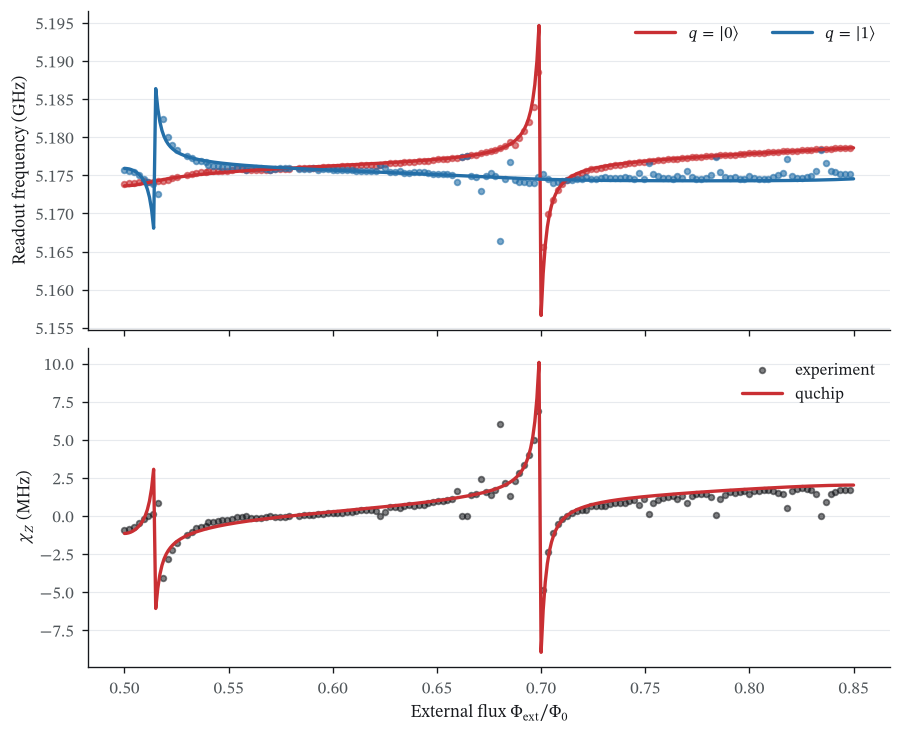

In [10]:
readout_figure, (frequency_axis, chi_axis) = plt.subplots(
    2,
    1,
    figsize=(7.4, 6.0),
    sharex=True,
    layout="constrained",
)
frequency_axis.scatter(readout_flux, measured_fr0, s=12, color="#C92F33", alpha=0.6)
frequency_axis.scatter(readout_flux, measured_fr1, s=12, color="#246FA8", alpha=0.6)
frequency_axis.plot(
    readout_model_flux,
    predicted_fr0_grid,
    color="#C92F33",
    label=r"$q=|0\rangle$",
)
frequency_axis.plot(
    readout_model_flux,
    predicted_fr1_grid,
    color="#246FA8",
    label=r"$q=|1\rangle$",
)
frequency_axis.set_ylabel("Readout frequency (GHz)")
frequency_axis.legend(ncols=2)

chi_axis.scatter(
    readout_flux,
    measured_chi_mhz,
    s=12,
    color="#16181C",
    alpha=0.55,
    label="experiment",
)
chi_axis.plot(
    readout_model_flux,
    predicted_chi_grid_mhz,
    color="#C92F33",
    linewidth=2.0,
    label="quchip",
)
chi_axis.set(
    xlabel=r"External flux $\Phi_{\mathrm{ext}}/\Phi_0$",
    ylabel=r"$\chi_Z$ (MHz)",
)
chi_axis.legend()

if docs.is_dir():
    readout_figure.savefig(docs / "images/stefanski_fluxonium_readout.svg")
plt.show()

</details>

```{figure} ../images/stefanski_fluxonium_readout.svg
:width: 720px
:alt: Measured and predicted state-dependent readout resonator frequencies and dispersive shift across external flux

The same chip reproduces the state-dependent readout frequencies and the
higher-level resonances in the dispersive shift.
```

The paper operates at the sweet spot for idle and control, then pulses to
$\Phi_{\mathrm{ext}}/\Phi_0=0.6567$ during readout. These two points give
a compact numerical check against the values in the text, and both sets of
dispersive coefficients below use quchip's $\chi_Z$ convention.

In [11]:
sweet_spot = readout_observables(0.5)
flux_pulsed = readout_observables(0.6567)

print("Sweet spot, flux 0.5:")
print(f"  f01   paper 0.377 GHz, quchip {isolated_f01(0.5):.4f} GHz")
print(f"  fr0   paper 5.1739 GHz, quchip {sweet_spot[0]:.4f} GHz")
print(f"  chi_Z paper -0.92 MHz, quchip {sweet_spot[2]:.3f} MHz")
print("Flux-pulsed readout, flux 0.6567:")
print(f"  f01   paper 3.47 GHz, quchip {isolated_f01(0.6567):.4f} GHz")
print(f"  chi_Z paper 1.09 MHz, quchip {flux_pulsed[2]:.3f} MHz")

Sweet spot, flux 0.5:
  f01   paper 0.377 GHz, quchip 0.3723 GHz
  fr0   paper 5.1739 GHz, quchip 5.1736 GHz
  chi_Z paper -0.92 MHz, quchip -1.142 MHz
Flux-pulsed readout, flux 0.6567:
  f01   paper 3.47 GHz, quchip 3.4802 GHz
  chi_Z paper 1.09 MHz, quchip 1.135 MHz


<details>
<summary>Numerical record</summary>

In [12]:
resonator_residual_mhz = 1.0e3 * np.concatenate(
    [predicted_fr0_at_data - measured_fr0, predicted_fr1_at_data - measured_fr1]
)
chi_residual_mhz = predicted_chi_at_data_mhz - measured_chi_mhz

paper_receipt = {
    "chi_median_absolute_error_mhz": round(float(np.median(np.abs(chi_residual_mhz))), 4),
    "chi_rmse_mhz": round(float(np.sqrt(np.mean(chi_residual_mhz**2))), 4),
    "readout_frequency_rmse_mhz": round(float(np.sqrt(np.mean(resonator_residual_mhz**2))), 4),
    "readout_points": len(readout_flux),
    "readout_model_points": len(readout_model_flux),
    "spectrum_median_absolute_error_mhz": round(spectrum_check["median_absolute_error_mhz"], 4),
    "spectrum_p95_absolute_error_mhz": round(spectrum_check["p95_absolute_error_mhz"], 4),
    "spectrum_points": len(paper_flux),
    "spectrum_model_points": len(paper_model_flux),
}

print(
    "RESULT paper_statics="
    + json.dumps(paper_receipt, sort_keys=True, separators=(",", ":"))
)

RESULT paper_statics={"chi_median_absolute_error_mhz":0.1767,"chi_rmse_mhz":0.7652,"readout_frequency_rmse_mhz":1.0848,"readout_model_points":351,"readout_points":151,"spectrum_median_absolute_error_mhz":1.5924,"spectrum_model_points":351,"spectrum_p95_absolute_error_mhz":6.0768,"spectrum_points":153}


</details>

The authors fitted the circuit parameters to these measurements, so use
this result as a cross-implementation check of their static model, while a
fabrication-level prediction needs independent circuit parameters.

## Fit measured spectroscopy

The authors fitted the spectrum to get $E_C$, $E_J$, and $E_L$, and here we
start away from their parameters and minimize a differentiable quchip loss.

Every eighth measurement goes into the fit, and the points between them
are held out. The plotted model uses its own 351-point flux grid.

In [13]:
import jax
import jax.numpy as jnp
from scipy.optimize import minimize

published_energies = np.asarray([paper_E_C, paper_E_J, paper_E_L])
measured_flux = paper_flux

training_indices = np.arange(0, measured_flux.size, 8)
holdout_mask = np.ones(measured_flux.size, dtype=bool)
holdout_mask[training_indices] = False
training_flux = jnp.asarray(measured_flux[training_indices])
training_f01 = jnp.asarray(measured_f01[training_indices])

The optimization model uses a 160-point phase grid. Logarithmic coordinates
keep the three circuit energies positive and put them on comparable numerical
scales.

In [14]:
fit_q = Fluxonium(
    E_C=0.72,
    E_J=4.4,
    E_L=0.68,
    phi_ext=0.5,
    levels=4,
    num_basis=160,
    phi_max=5.0 * np.pi,
    basis="eigen",
    label="q",
)
fit_chip = Chip(
    [fit_q],
    [],
    basis="eigen",
    frame="lab",
    backend="dynamiqs",
)

energy_scale = jnp.asarray([1.0, 4.0, 1.0])
initial_energies = np.asarray([0.72, 4.4, 0.68])
initial_coordinates = jnp.log(jnp.asarray(initial_energies) / energy_scale)


def energies_from_coordinates(coordinates):
    return energy_scale * jnp.exp(coordinates)


def fluxonium_f01(energies, phi_ext):
    point = fit_chip.with_params(
        {
            "q.E_C": energies[0],
            "q.E_J": energies[1],
            "q.E_L": energies[2],
            "q.phi_ext": phi_ext,
        }
    )
    return point.freq("q")


def spectrum_prediction(coordinates, flux):
    energies = energies_from_coordinates(coordinates)
    return jax.vmap(lambda phi: fluxonium_f01(energies, phi))(flux)

Fit a smooth robust loss, which limits the influence of spectroscopy
outliers, with SciPy's bounded optimizer and the loss gradient from JAX.

In [15]:
def pseudo_huber(residual):
    return 2.0 * (jnp.sqrt(1.0 + residual**2) - 1.0)


def experimental_loss(coordinates):
    residual_mhz = 1.0e3 * (
        spectrum_prediction(coordinates, training_flux) - training_f01
    )
    return jnp.mean(pseudo_huber(residual_mhz / 3.0))


compiled_loss_and_gradient = jax.jit(jax.value_and_grad(experimental_loss))
loss_history = []


def scipy_objective(coordinates):
    value, gradient = compiled_loss_and_gradient(jnp.asarray(coordinates))
    return float(value), np.asarray(gradient, dtype=float)


fit = minimize(
    scipy_objective,
    np.asarray(initial_coordinates),
    method="L-BFGS-B",
    jac=True,
    bounds=[
        (np.log(0.3), np.log(1.5)),
        (np.log(2.0 / 4.0), np.log(6.0 / 4.0)),
        (np.log(0.3), np.log(1.5)),
    ],
    callback=lambda coordinates: loss_history.append(
        scipy_objective(coordinates)[0]
    ),
    options={"maxiter": 160, "ftol": 1.0e-12, "gtol": 1.0e-9},
)

recovered_energies = np.asarray(
    energies_from_coordinates(jnp.asarray(fit.x)),
    dtype=float,
)

The evaluation computes the model on a new 351-point flux grid and then
interpolates it at the held-out measurement coordinates for the residual
check.

In [16]:
model_flux = jnp.linspace(0.5, 0.85, 351)
model_f01 = np.asarray(spectrum_prediction(jnp.asarray(fit.x), model_flux))
predicted_at_measurements = np.interp(
    measured_flux,
    np.asarray(model_flux),
    model_f01,
)
holdout_residual_mhz = 1.0e3 * (
    predicted_at_measurements[holdout_mask] - measured_f01[holdout_mask]
)

<details>
<summary>Plotting code</summary>

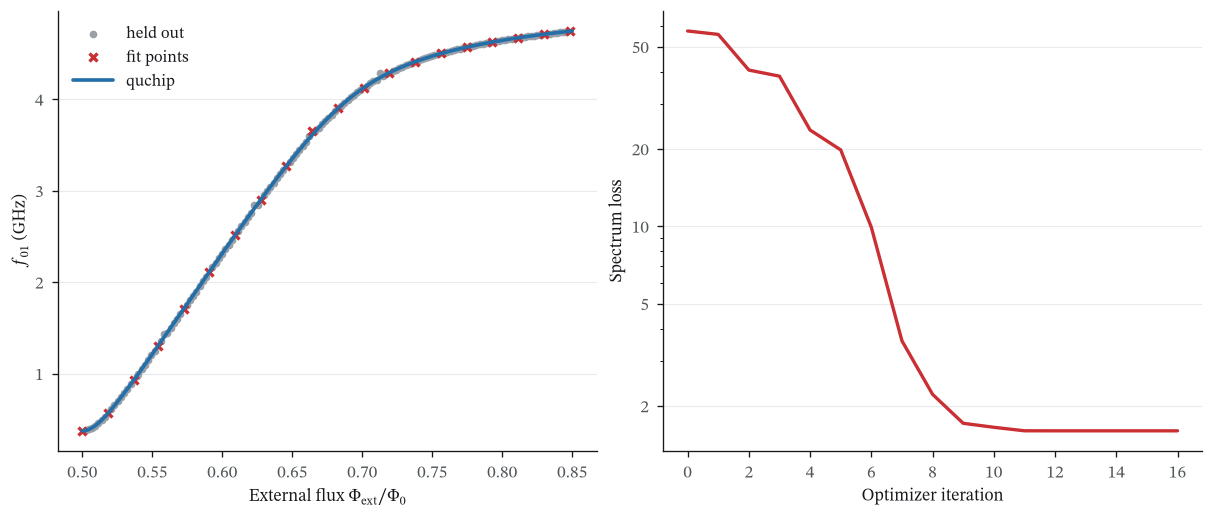

In [17]:
from matplotlib.ticker import LogLocator, MaxNLocator, NullFormatter, ScalarFormatter

fit_figure, (fit_axis, history_axis) = plt.subplots(
    1,
    2,
    figsize=(10.0, 4.2),
    layout="constrained",
)
fit_axis.scatter(
    measured_flux[holdout_mask],
    measured_f01[holdout_mask],
    s=13,
    color="#9AA0A8",
    label="held out",
)
fit_axis.scatter(
    measured_flux[training_indices],
    measured_f01[training_indices],
    s=23,
    color="#C92F33",
    marker="x",
    label="fit points",
)
fit_axis.plot(model_flux, model_f01, color="#246FA8", linewidth=2.2, label="quchip")
fit_axis.set(
    xlabel=r"External flux $\Phi_{\mathrm{ext}}/\Phi_0$",
    ylabel=r"$f_{01}$ (GHz)",
)
fit_axis.legend()

history_axis.semilogy(loss_history, color="#C92F33", linewidth=2.0)
history_axis.set(xlabel="Optimizer iteration", ylabel="Spectrum loss")
history_axis.yaxis.set_major_locator(LogLocator(subs=(1.0, 2.0, 5.0)))
history_axis.yaxis.set_major_formatter(ScalarFormatter())
history_axis.yaxis.set_minor_formatter(NullFormatter())
history_axis.xaxis.set_major_locator(MaxNLocator(integer=True))

if docs.is_dir():
    fit_figure.savefig(docs / "images/differentiate_fluxonium_fit.svg")
plt.show()

</details>

```{figure} ../images/differentiate_fluxonium_fit.svg
:width: 760px
:alt: Fluxonium spectrum fitted on sparse experimental points with held-out measurements and convergence history

Twenty measurements determine the loss. The remaining 133 points test the
recovered spectrum.
```

<details>
<summary>Numerical record</summary>

In [18]:
experimental_fit_receipt = {
    "fit_success": bool(fit.success),
    "training_points": len(training_indices),
    "holdout_points": int(holdout_mask.sum()),
    "published_E_C_E_J_E_L": np.round(published_energies, 5).tolist(),
    "initial_E_C_E_J_E_L": initial_energies.tolist(),
    "recovered_E_C_E_J_E_L": np.round(recovered_energies, 5).tolist(),
    "relative_parameter_error": np.round(
        (recovered_energies - published_energies) / published_energies, 5
    ).tolist(),
    "holdout_median_absolute_error_mhz": round(float(np.median(np.abs(holdout_residual_mhz))), 3),
    "holdout_rmse_mhz": round(float(np.sqrt(np.mean(holdout_residual_mhz**2))), 3),
}

print(
    "RESULT experimental_statics="
    + json.dumps(experimental_fit_receipt, sort_keys=True, separators=(",", ":"))
)

RESULT experimental_statics={"fit_success":true,"holdout_median_absolute_error_mhz":0.881,"holdout_points":133,"holdout_rmse_mhz":6.967,"initial_E_C_E_J_E_L":[0.72,4.4,0.68],"published_E_C_E_J_E_L":[0.86527,3.82174,0.82158],"recovered_E_C_E_J_E_L":[0.87042,3.82036,0.82086],"relative_parameter_error":[0.00595,-0.00036,-0.00088],"training_points":20}


</details>

The recovered circuit energies are within $0.6\%$ of the authors' values.
The few large spectroscopy residuals stay in the holdout RMSE, while the
median error is $0.88$ MHz. This section fits the isolated fluxonium
spectrum, while the paper's full fit also included the coupled readout
resonator.